In [1]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import cmocean
import cartopy.crs as ccrs

In [2]:
import healpy

In [6]:
from bin_to_healpix import open_sparse_hpx

In [3]:
plt.style.use("../nice.mplstyle")

In [8]:
ds2 = xr.open_dataset("data/l2p/dataset-l2p-uncross-calibrated-ntc-sla-j1_20080227_merged.nc")
hds25 = open_sparse_hpx("data/healpix/l2p_j1_sea_level_anomaly_L5_20080227_sparse.nc")
hds26 = open_sparse_hpx("data/healpix/l2p_j1_sea_level_anomaly_L6_20080227_sparse.nc")
hds27 = open_sparse_hpx("data/healpix/l2p_j1_sea_level_anomaly_L7_20080227_sparse.nc")
hds29 = open_sparse_hpx("data/healpix/l2p_j1_sea_level_anomaly_L9_20080227_sparse.nc")

hds25 = hds25.rename({"lon": "longitude", "lat": "latitude"})
hds26 = hds26.rename({"lon": "longitude", "lat": "latitude"})
hds27 = hds27.rename({"lon": "longitude", "lat": "latitude"})
hds29 = hds29.rename({"lon": "longitude", "lat": "latitude"})

In [13]:
ds3 = xr.open_dataset("data/l3/dt_global_j1_phy_l3_1hz_20080227_20240205.nc")
hds35 = open_sparse_hpx("data/healpix/l3_j1_sla_filtered_L5_20080227_sparse.nc")
hds36 = open_sparse_hpx("data/healpix/l3_j1_sla_filtered_L6_20080227_sparse.nc")
hds37 = open_sparse_hpx("data/healpix/l3_j1_sla_filtered_L7_20080227_sparse.nc")
hds39 = open_sparse_hpx("data/healpix/l3_j1_sla_filtered_L9_20080227_sparse.nc")

hds35 = hds35.rename({"lon": "longitude", "lat": "latitude"})
hds36 = hds36.rename({"lon": "longitude", "lat": "latitude"})
hds37 = hds37.rename({"lon": "longitude", "lat": "latitude"})
hds39 = hds39.rename({"lon": "longitude", "lat": "latitude"})

In [29]:
def big_plot(l2plist, l3list=None, varnames=("sea_level_anomaly", "sla_filtered")):
    
    nrows = len(l2plist)
    ncols = 1 if l3list is None else 2
    fig, axs = plt.subplots(nrows, ncols, figsize=(6*ncols,3*nrows), subplot_kw={"projection": ccrs.Robinson()})
    
    if l3list is None:
        axs = np.asarray([axs])

    for xdslist, varname, axc in zip(
        [l2plist, l3list],
        varnames,
        axs.T,
    ):
        
        for xds, ax in zip(xdslist, axc):
            xda = xds[varname]
            vmax = 1.5 if varname != "obs_count" else xda.max().values
            ax.scatter(
                xda.longitude,
                xda.latitude,
                c=xda,
                transform=ccrs.PlateCarree(),
                cmap="cmo.balance" if varname != "obs_count" else "cmo.dense",
                vmin=-vmax if varname != "obs_count" else 0,
                vmax=vmax,
            )

            if varname == "obs_count":
                ax.text(.7, .1, f"Nmax = {vmax}", transform=ax.transAxes)
            ax.coastlines("50m")
    return fig, axs

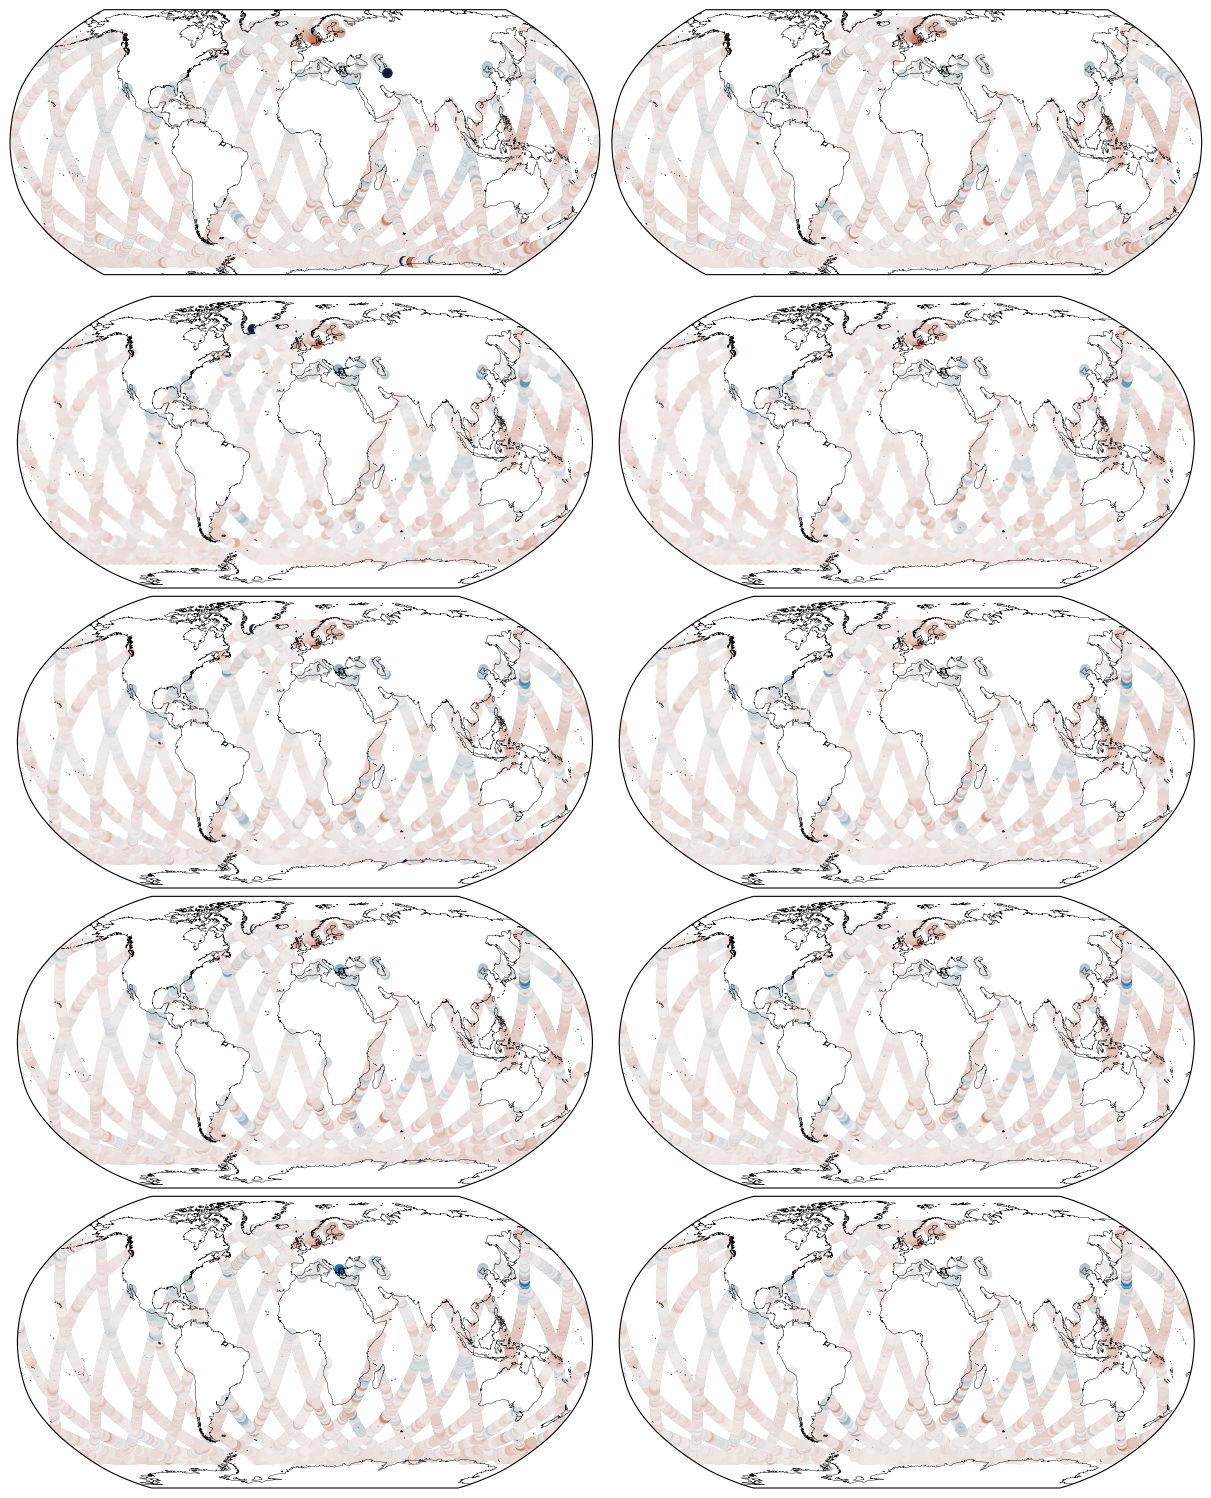

In [30]:
fig, axs = big_plot(
    [ds2, hds25, hds26, hds27, hds29],
    [ds3, hds35, hds36, hds37, hds39],
)

[None, None, None, None, None, None, None, None, None, None]

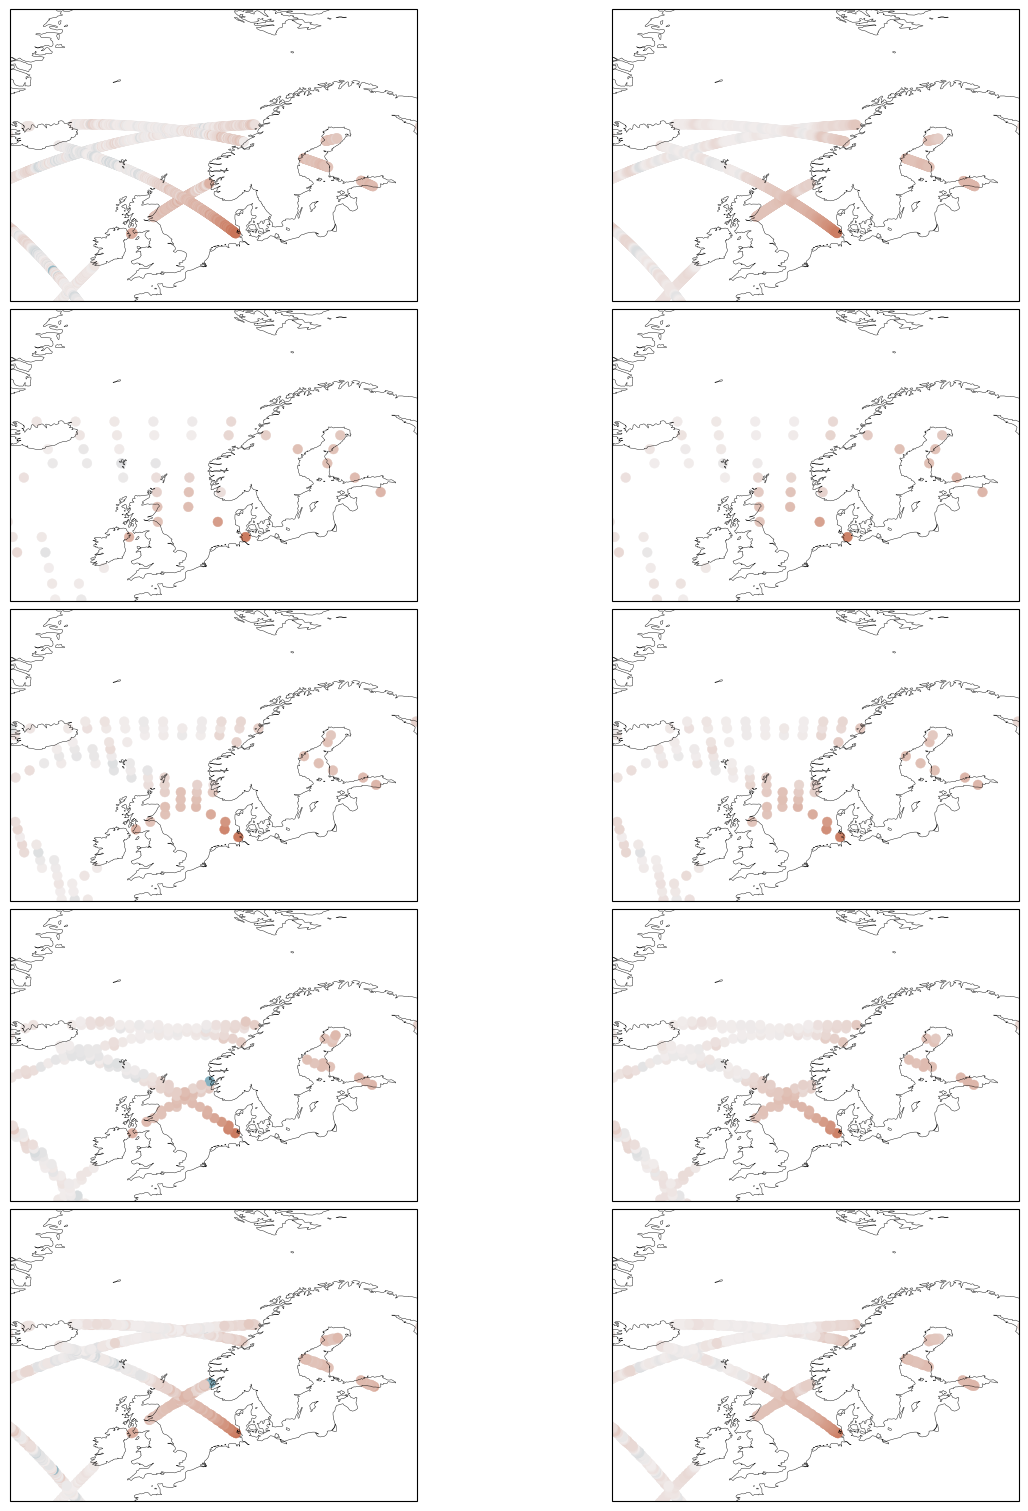

In [33]:
fig, axs = big_plot(
    [ds2.where(ds2.validation_flag == 0), hds25, hds26, hds27, hds29],
    [ds3, hds35, hds36, hds37, hds39],
)
[ax.set_extent([-20, 30, 48, 80], crs=ccrs.PlateCarree()) for ax in axs.flatten()]

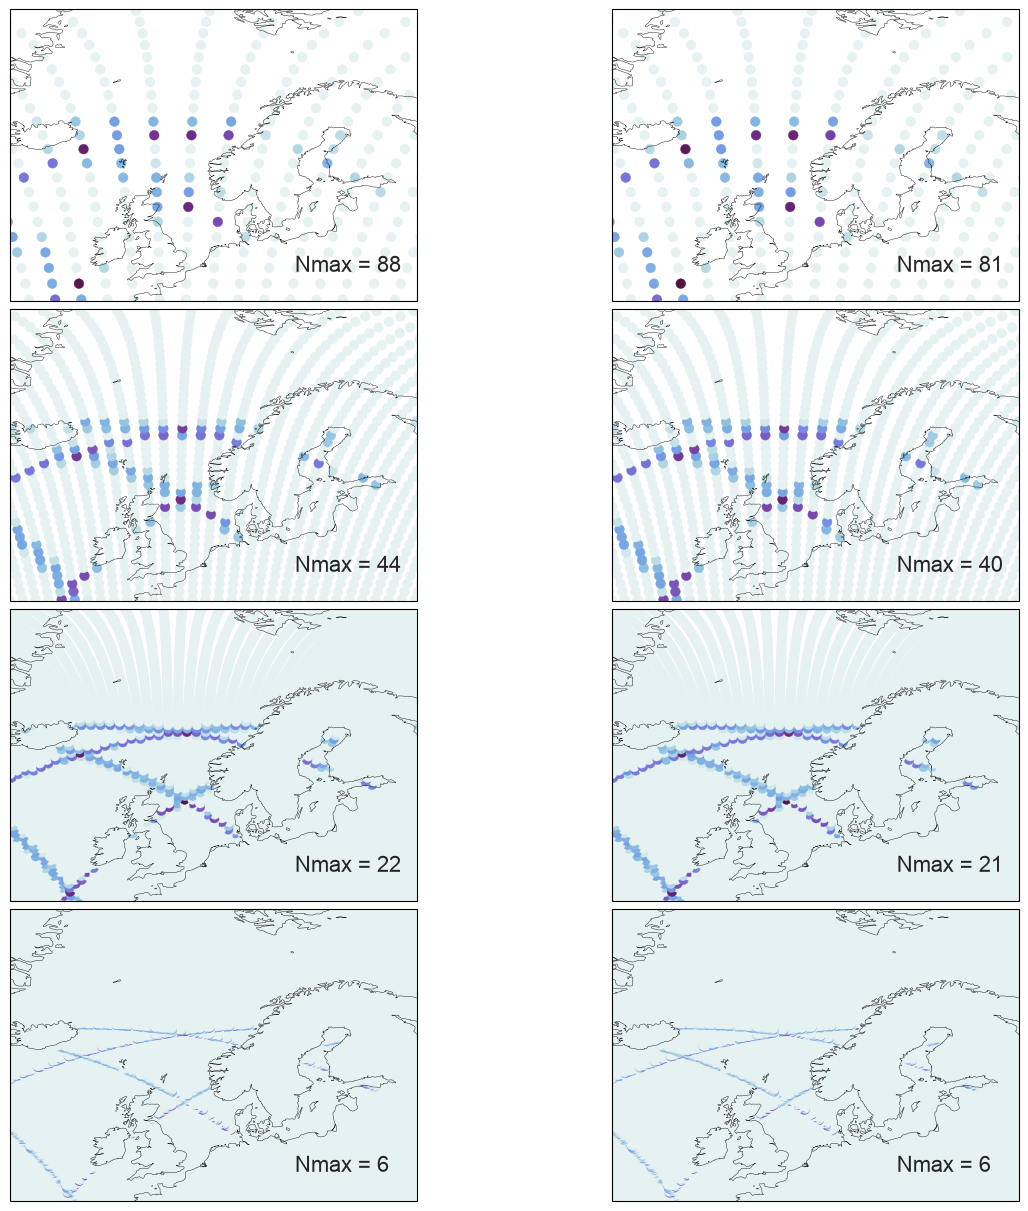

In [31]:
fig, axs = big_plot(
    [hds25, hds26, hds27, hds29],
    [hds35, hds36, hds37, hds39],
    varnames=["obs_count", "obs_count"],
)
for ax in axs.flatten():
    ax.set_extent([-20, 30, 48, 80], crs=ccrs.PlateCarree())

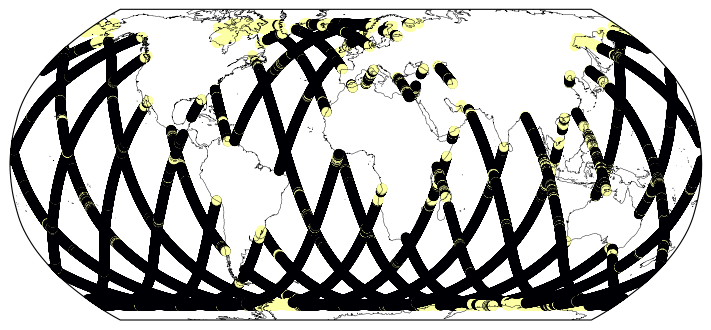

In [32]:
fig, ax = plt.subplots(subplot_kw={"projection": ccrs.Robinson()})

ax.scatter(
    ds2.longitude,
    ds2.latitude,
    c=ds2.validation_flag,
    transform=ccrs.PlateCarree()
) 
ax.coastlines("50m")

In [73]:
ds2.sea_level_anomaly.where(ds2.validation_flag == 0, drop=True)

<xarray.DataArray 'sea_level_anomaly' (time: 41357)> Size: 331kB
array([ 0.0481, -0.0301,  0.0489, ...,  0.1222,  0.1074,  0.1514],
      shape=(41357,))
Coordinates:
  * time       (time) datetime64[ns] 331kB 2010-07-16T00:22:02.874289984 ... ...
    latitude   (time) float64 331kB -56.33 -56.27 -56.22 ... 79.03 79.09 79.14
    longitude  (time) float64 331kB 14.45 14.44 14.43 ... 3.562 3.503 3.443
Attributes:
    quality_flag:   validation_flag
    comment:        altitude of satellite (altitude) - ocean altimeter range ...
    long_name:      sea level anomaly
    standard_name:  sea_surface_height_above_sea_level
    units:          m

In [ ]:
ds2